# Задача 2.5
a) Найти решение уравнения Пуассона с граничными условиями Дирихле по оси $x$ и периодическими условиями по оси $y$:

$$
\begin{cases}
\Delta u = 4 - 29 \sin (5x + 2y), & -1 < x < 1, \quad 0 < y < \pi, \\
u(-1, y) = 2 + \sin (2y - 5), & u(1, y) = 2 + \sin (2y + 5), \\
u(x, y + \pi) = u(x, y).
\end{cases}
$$

Точное решение: $\quad u_0(x, y) = 2x^2 + \sin(5x + 2y).$

б) 
Между обкладками бесконечного конденсатора помещены два заряда — 𝑞1 и 𝑞2.
Построить линии напряженности электростатического поля
Поместим два точечных заряда - положительный в точку $(-0.4, \frac{\pi}{2})$ и отрицательный в точку $(0.4, \frac{\pi}{2})$.
$$
\begin{cases}
\Delta u = -\left[\delta(x + 0.4, y - \frac{\pi}{2}) - \delta(x - 0.4, y - \frac{\pi}{2})\right], & -1 < x < 1, \quad 0 < y < \pi, \\
u(-1, y) = -1, \quad u(1, y) = 1, \\
u(x, y + \pi) = u(x, y).
\end{cases}
$$
После нахождения потенциала $u(x, y)$ вычисляется вектор напряженности электростатического поля:
$$\mathbf{E} = -\nabla u = \left(-\frac{\partial u}{\partial x}, \, -\frac{\partial u}{\partial y}\right)$$

In [1]:
import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt
import time

In [5]:
def u_0(x, y):
    return 2 * x ** 2 + np.sin(5 * x + 2 * y)

In [3]:
def OpL():
    k = np.arange(nx*ny, dtype=int).reshape((nx, ny))
    I, J = np.meshgrid(np.arange(nx), np.arange(ny))
    I, J = I.flatten(), J.flatten()

    iC = k[I, J].flatten()
    iB = k[I, (J-1)%ny].flatten()
    iT = k[I, (J+1)%ny].flatten()

    iNR = k[-1, :].flatten()
    iHR = k[:-1,:].flatten()
    iR = k[1:,:].flatten()

    iNL = k[0 ,:].flatten()
    iHL = k[1:,:].flatten()
    iL = k[:-1,:].flatten()

    R1, C1, V1 = iC, iC, np.full(iC.size, +2.0/hy**2)
    R2, C2, V2 = iC, iB, np.full(iC.size, -1.0/hy**2)
    R3, C3, V3 = iC, iT, np.full(iC.size, -1.0/hy**2)

    R4, C4, V4 = iHL, iHL, np.full(iHL.size, +1.0/hx**2)
    R5, C5, V5 = iHL, iL, np.full(iHL.size, -1.0/hx**2)

    R6, C6, V6 = iHR, iHR, np.full(iHR.size, +1.0/hx**2)
    R7, C7, V7 = iHR, iR, np.full(iHR.size, -1.0/hx**2)

    R8, C8, V8 = iNL, iNL, np.full(iNL.size, +2.0/hx**2)

    #Правая граница, узлы, у которых нет правых соседей
    R9, C9, V9 = iNR, iNR, np.full(iNR.size, +2.0 / hx**2)

    row = np.concatenate((R1, R2, R3, R4, R5, R6, R7, R8, R9))
    col = np.concatenate((C1, C2, C3, C4, C5, C6, C7, C8, C9))
    val = np.concatenate((V1, V2, V3, V4, V5, V6, V7, V8, V9))

    L = sp.csr_matrix((val,(row,col)))
    return L

In [6]:
nx, ny = 300, 300
N = nx*ny
hx = 2.0 / nx
hy = np.pi / ny

x = np.linspace(-1.0 + hx/2.0, 1.0 - hx/2.0, nx)
y = np.linspace(hy/2.0, np.pi - hy/2.0, ny)

X, Y = np.meshgrid(x, y, indexing='ij')

u_exact = u_0(X, Y)

L = OpL()

F = -(4 - 29 * np.sin(5 * X + 2 * Y))
F[0, :] += 2 * (2 + np.sin(2 * Y[0, :] - 5)) / hx**2
F[-1, :] += 2 * (2 + np.sin(2 * Y[-1, :] + 5)) / hx**2
F = F.ravel()

t0 = time.perf_counter()
u1 = sp.linalg.spsolve(L, F)
solve_time = time.perf_counter() - t0
u1 = u1.reshape((nx, ny))

print(f"Погрешность: {np.max(np.abs(u_exact - u1))}")
print(f"Количество эелементов: {L.shape[0]*L.shape[1]}, количество ненулевых элементов: {L.nnz}")
matrix_mem_mb = (L.data.nbytes + L.indices.nbytes + L.indptr.nbytes) / (1024 ** 2)
print(f"Время, затраченное на вычисление: {solve_time} с")
print(f"Затраты памяти на хранение матрицы: {matrix_mem_mb} Мб")

Погрешность: 0.0001607416011309981
Количество эелементов: 8100000000, количество ненулевых элементов: 449400
Время, затраченное на вычисление: 5.983904199999984 с
Затраты памяти на хранение матрицы: 5.486301422119141 Мб


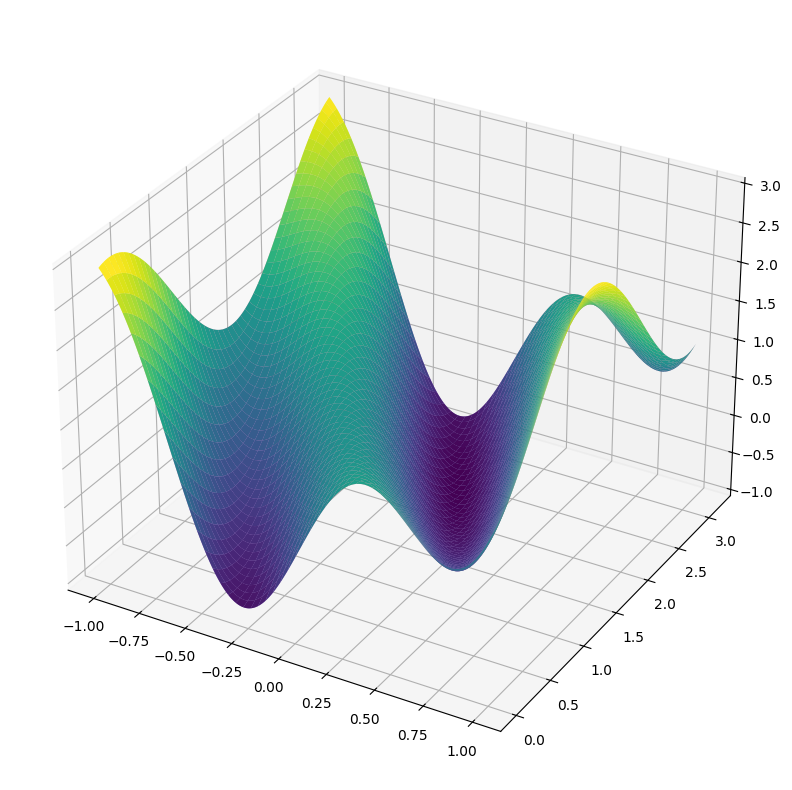

In [7]:
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(X, Y, u_exact, cmap='viridis')
ax.plot_surface(X, Y, u1, cmap='plasma', alpha=0.5)
plt.show()

Порядок точности: 1.9948282149541225


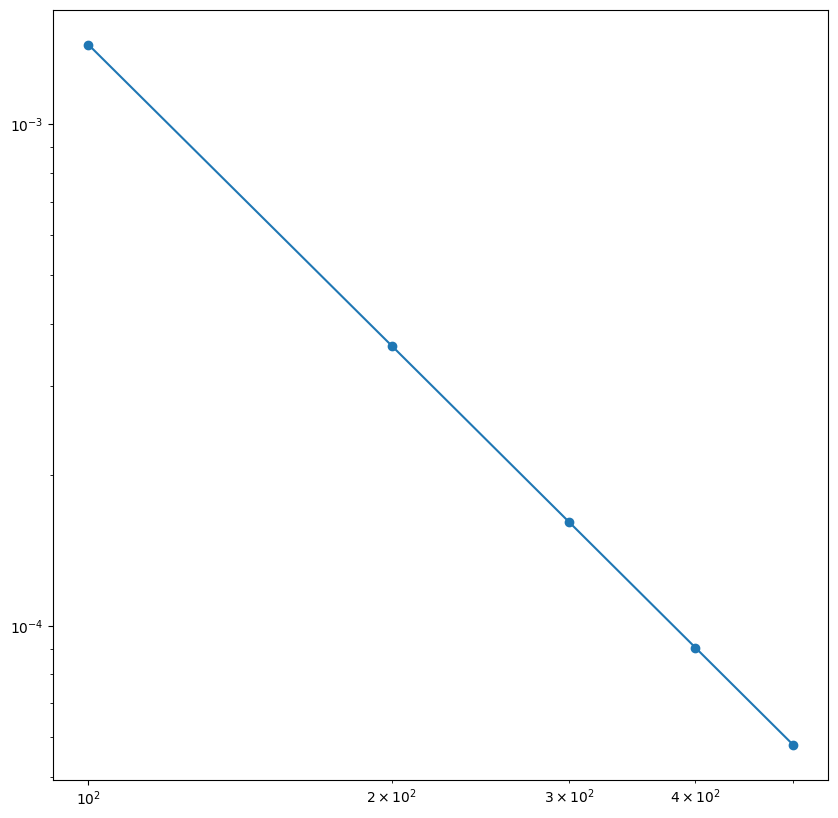

In [8]:
grid_sizes = [100, 200, 300, 400, 500]
errors = []
times = []
amount_of_nz_elements = []
memory = []
for n in grid_sizes:
    nx, ny = n, n
    N = nx*ny
    hx = 2.0 / nx
    hy = np.pi / ny

    x = np.linspace(-1.0 + hx/2.0, 1.0 - hx/2.0, nx)
    y = np.linspace(hy/2.0, np.pi - hy/2.0, ny)

    X, Y = np.meshgrid(x, y, indexing='ij')

    u_exact = u_0(X, Y)

    L = OpL()

    F = -(4 - 29 * np.sin(5 * X + 2 * Y))
    F[0, :] += 2 * (2 + np.sin(2 * Y[0, :] - 5)) / hx**2
    F[-1, :] += 2 * (2 + np.sin(2 * Y[-1, :] + 5)) / hx**2
    F = F.ravel()

    t0 = time.perf_counter()
    u1 = sp.linalg.spsolve(L, F)
    solve_time = time.perf_counter() - t0
    u1 = u1.reshape((nx, ny))

    matrix_mem_mb = (L.data.nbytes + L.indices.nbytes + L.indptr.nbytes) / (1024 ** 2)
    errors.append(np.max(np.abs(u_exact - u1)))
    times.append(solve_time)
    amount_of_nz_elements.append(L.nnz)
    memory.append(matrix_mem_mb)

plt.figure(figsize=(10, 10))
plt.loglog(grid_sizes, errors)
plt.scatter(grid_sizes, errors)
print(f"Порядок точности: {-((np.log(errors[1]) - np.log(errors[0])) / (np.log(grid_sizes[1]) - np.log(grid_sizes[0])))}")

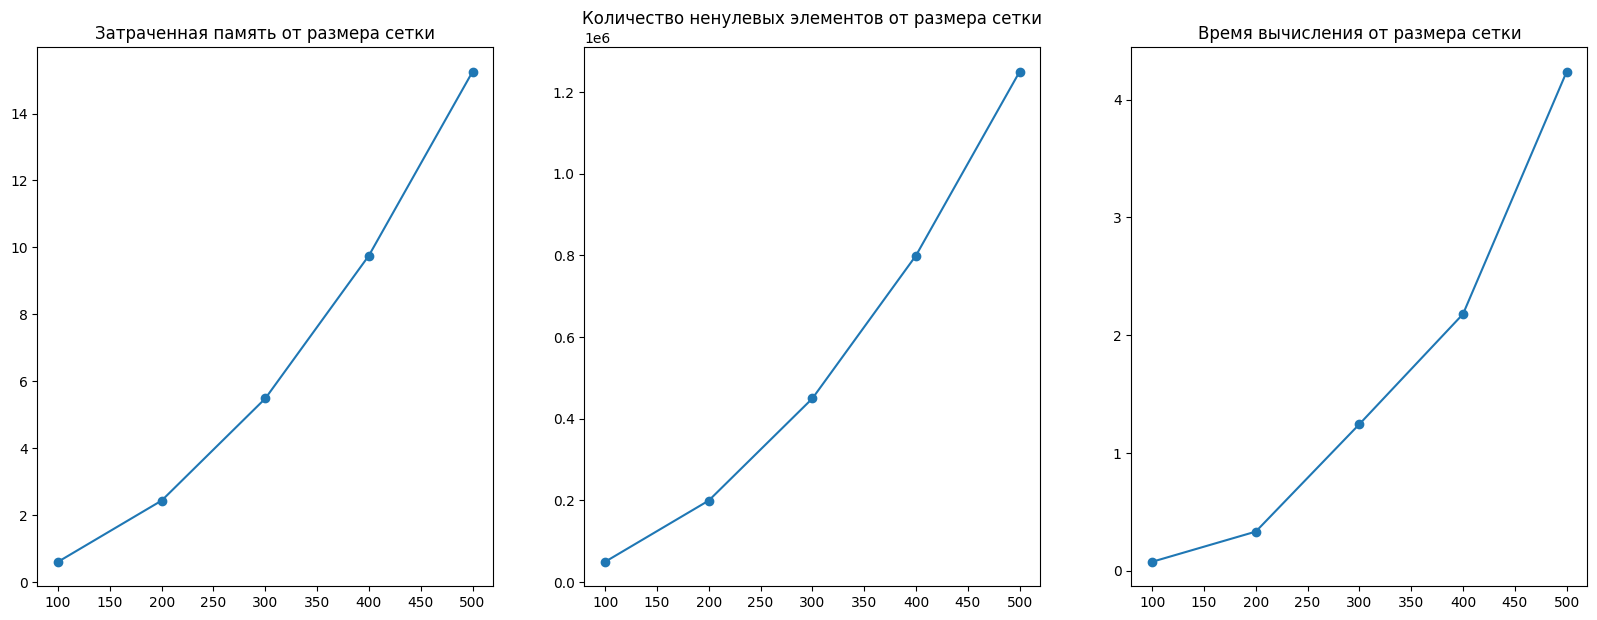

In [9]:
plt.figure(figsize=(20, 7))
plt.subplot(1, 3, 1)
plt.plot(grid_sizes, memory)
plt.scatter(grid_sizes, memory)
plt.title("Затраченная память от размера сетки")

plt.subplot(1, 3, 2)
plt.plot(grid_sizes, amount_of_nz_elements)
plt.scatter(grid_sizes, amount_of_nz_elements)
plt.title("Количество ненулевых элементов от размера сетки")

plt.subplot(1, 3, 3)
plt.plot(grid_sizes, times)
plt.scatter(grid_sizes, times)
plt.title("Время вычисления от размера сетки")

plt.show()

In [10]:
nx, ny = 300, 300
N = nx*ny
hx = 2.0 / nx
hy = np.pi / ny

x = np.linspace(-1.0 + hx/2.0, 1.0 - hx/2.0, nx)
y = np.linspace(hy/2.0, np.pi - hy/2.0, ny)

X, Y = np.meshgrid(x, y, indexing='ij')

#Координаты зарядов и значение зарядов
x1, y1, q1 = -0.4, np.pi / 2,  1.0
x2, y2, q2 =  0.4, np.pi / 2, -1.0

rho = np.zeros((nx, ny))

#Номера узлов, в которых находятся точечные заряды
i1 = int((x1 - (-1.0)) / hx)
j1 = int((y1 - 0.0) / hy)

i2 = int((x2 - (-1.0)) / hx)
j2 = int((y2 - 0.0) / hy)

#Вычисление поверхностной плотности заряда в узлах с зарядами
rho[i1, j1] += q1 / (hx * hy)
rho[i2, j2] += q2 / (hx * hy)

#Потенциал на границах конденсатора
V1 = -1
V2 = 1

L = OpL()

F = rho
F[0, :] += 2 * V1 / hx**2
F[-1, :] += 2 * V2 / hx**2
F = F.ravel()

t0 = time.perf_counter()
u1 = sp.linalg.spsolve(L, F)
solve_time = time.perf_counter() - t0
u1 = u1.reshape((nx, ny))

print(f"Количество эелементов: {L.shape[0]*L.shape[1]}, количество ненулевых элементов: {L.nnz}")
matrix_mem_mb = (L.data.nbytes + L.indices.nbytes + L.indptr.nbytes) / (1024 ** 2)
print(f"Время, затраченное на вычисление: {solve_time} с")
print(f"Затраты памяти на хранение матрицы: {matrix_mem_mb} Мб")

Количество эелементов: 8100000000, количество ненулевых элементов: 449400
Время, затраченное на вычисление: 1.334906100000012 с
Затраты памяти на хранение матрицы: 5.486301422119141 Мб


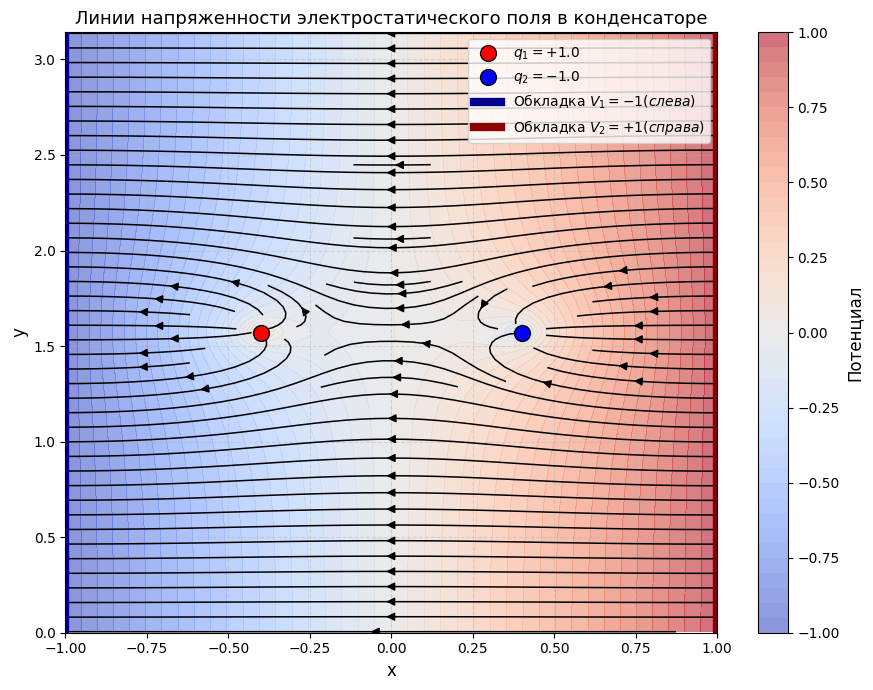

In [13]:
dU_dx, dU_dy = np.gradient(u1, hx, hy)
Ex = -dU_dx
Ey = -dU_dy


plt.figure(figsize=(9, 7))

#Цветовая карта потенциала
cp = plt.contourf(x, y, u1.T, levels=40, cmap='coolwarm', alpha=0.6)
cbar = plt.colorbar(cp)
cbar.set_label('Потенциал', fontsize=12)

#Линии напряженности поля
plt.streamplot(x, y, Ex.T, Ey.T, color='black', linewidth=1.1, density=1.4, arrowsize=1.2)

#Заряды
plt.scatter(x1, y1, color='red', s=130, edgecolors='black', zorder=5, label=f'$q_1 = +{q1}$')
plt.scatter(x2, y2, color='blue', s=130, edgecolors='black', zorder=5, label=f'$q_2 = {q2}$')

#Обкладки конденсатора
plt.axvline(-1.0, color='darkblue', linewidth=6, label=f'Обкладка $V_1 = {V1} (слева)$')
plt.axvline( 1.0, color='darkred',  linewidth=6, label=f'Обкладка $V_2 = +{V2} (справа)$')

plt.title("Линии напряженности электростатического поля в конденсаторе", fontsize=13)
plt.xlabel("x", fontsize=12)
plt.ylabel("y", fontsize=12)
plt.xlim(-1.0, 1.0)
plt.ylim(0.0, np.pi)
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()